# 05 – Mô hình sâu trên Res16: BERT fine-tune, mô hình lai GRU→BiLSTM→Attention (có mask) và ablation thật

**Chạy trên Kaggle (GPU T4) hoặc Colab.** Cần: `src/absa_common.py`, `src/absa_torch.py` và dữ liệu XML (xem README).
Thời gian: ~30–60 phút trên GPU T4. Trên CPU, mỗi lần fine-tune BERT ≈ 1,5–2 giờ (6 lần ≈ 10 giờ, nằm ở mục A).

**Cùng giao thức với notebook 04** để so sánh được: validation tách từ train theo review, chọn epoch bằng Macro F1 trên
validation, test chỉ đo một lần ở epoch tốt nhất, nhiều seed, báo cáo trung bình ± độ lệch chuẩn.

**Khác notebook 03 (bản gốc của nhóm) – có chủ đích:**

| | Notebook 03 | Notebook này |
|---|---|---|
| Chọn epoch | `val_accuracy` trên **test** | Macro F1 trên **validation** tách từ train |
| Padding | đệm cứng 256, không mask, ~90% vị trí là padding | đệm động, **mask ở mọi tầng** (RNN đóng gói, attention có key-padding mask, mean-pool có mask) |
| Chuẩn hoá sau Conv | BatchNorm (thống kê cả padding) | LayerNorm |
| Ablation | không có code | chạy thật, 5 seed |
| Lớp neutral | không xử lý | có thêm cấu hình class weight |

Kiến trúc đầu phân loại giữ nguyên ý tưởng nhóm (dựa trên CABiLSTM-BERT, He et al., 2025).

In [1]:
import os, sys, json, time, warnings
warnings.filterwarnings('ignore')
sys.path.append('../src')
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from absa_common import *
from absa_torch import *

# True = chạy thử nhanh bằng backbone ngẫu nhiên rất nhỏ (không cần mạng/GPU), CHỈ để kiểm tra code; số liệu vô nghĩa.
SMOKE = os.environ.get('ABSA_SMOKE', '0') == '1'
MAX_LEN = 128                      # EDA (notebook 01): 99,7% câu ≤ 96 token; 128 là dư
SEEDS_HEAD, SEEDS_FT = [0, 1, 2, 3, 4], [0, 1, 2]
EPOCHS_HEAD, PATIENCE_HEAD, LR_HEAD = 25, 6, 5e-4
EPOCHS_FT,   PATIENCE_FT,   LR_FT   = 6, 3, 2e-5
BACKBONES = {'bert-base-uncased': 'bert-base-uncased', 'roberta-base': 'roberta-base', 'deberta-v3-base': 'microsoft/deberta-v3-base'}
if SMOKE:
    SEEDS_HEAD, SEEDS_FT, EPOCHS_HEAD, PATIENCE_HEAD, EPOCHS_FT = [0, 1], [0], 2, 2, 1

device = get_device()
print('device:', device, '| SMOKE:', SMOKE)
os.makedirs('../results', exist_ok=True)

device: cpu | SMOKE: False


In [2]:
train_df, test_df = load_res16()
if SMOKE:
    train_df, test_df = train_df.iloc[:500].reset_index(drop=True), test_df.iloc[:150].reset_index(drop=True)
y_train = [LABEL2ID[p] for p in train_df.polarity]
y_test  = [LABEL2ID[p] for p in test_df.polarity]
SPLITS = {s: split_train_val(train_df, s) for s in sorted(set(SEEDS_HEAD) | set(SEEDS_FT))}
print(len(train_df), len(test_df), {s: (len(a), len(b)) for s, (a, b) in SPLITS.items()})

import pickle
RESULTS_PATH, PREDS_PATH = '../results/deep_results_runs.json', '../results/deep_preds.pkl'
RESULTS = json.load(open(RESULTS_PATH, encoding='utf-8')) if os.path.exists(RESULTS_PATH) else {}
PREDS   = pickle.load(open(PREDS_PATH, 'rb')) if os.path.exists(PREDS_PATH) else {}
def save_state():
    json.dump(RESULTS, open(RESULTS_PATH, 'w', encoding='utf-8'), default=float, ensure_ascii=False, indent=1)
    pickle.dump(PREDS, open(PREDS_PATH, 'wb'))

def load_backbone(key):
    """Trả về (tokenizer, factory) — factory() tạo backbone mới (để mỗi seed bắt đầu từ trọng số tiền huấn luyện)."""
    if SMOKE:
        return make_smoke_backbone(list(train_df.sentence) + list(test_df.sentence) + [aspect_text(a) for a in train_df.category])
    from transformers import AutoTokenizer, AutoModel
    name = BACKBONES[key]
    return AutoTokenizer.from_pretrained(name), (lambda: AutoModel.from_pretrained(name))

def report(name):
    r = RESULTS[name]
    print(f'{name:<42}', {k: v for k, v in summarize(r, cols=('acc', 'macro_f1', 'f1_neutral')).items()})

2507 859 {0: (2151, 356), 1: (2149, 358), 2: (2151, 356), 3: (2151, 356), 4: (2146, 361)}


## A. Baseline sâu: BERT fine-tune toàn bộ + vector [CLS]

Mốc quan trọng: nếu mô hình lai (mục B) không hơn được cấu hình đơn giản này, độ phức tạp thêm vào không có lợi.
`class_weight` bật/tắt để xem tác động lên lớp neutral.

In [3]:
tok, factory = load_backbone('bert-base-uncased')
Iall = encode_pairs(tok, train_df.category, train_df.sentence, MAX_LEN)
Ite  = encode_pairs(tok, test_df.category,  test_df.sentence,  MAX_LEN)
pad = tok.pad_token_id
for cw in (False, True):
    name = f'BERT fine-tune + [CLS]' + (' (class weight)' if cw else '')
    if name in RESULTS and len(RESULTS[name]) >= len(SEEDS_FT):
        print('[đã có, bỏ qua]', name); report(name); continue
    RESULTS[name] = []
    for s in SEEDS_FT:
        t0 = time.time(); tri, vai = SPLITS[s]
        r, p = finetune_cls(factory, pad, [Iall[i] for i in tri], [y_train[i] for i in tri],
                            [Iall[i] for i in vai], [y_train[i] for i in vai], Ite, y_test, seed=s,
                            epochs=EPOCHS_FT, patience=PATIENCE_FT, lr=LR_FT, class_weight=cw, device=device)
        RESULTS[name].append(r); PREDS[(name, s)] = p
        print(f'  {name} seed {s}: macro-F1={r["macro_f1"]*100:.2f} acc={r["acc"]*100:.2f} epoch*={r["best_epoch"]} ({time.time()-t0:.0f}s)')
    report(name)

[đã có, bỏ qua] BERT fine-tune + [CLS]
BERT fine-tune + [CLS]                     {'acc': '87.78 ± 0.71', 'macro_f1': '70.01 ± 1.49', 'f1_neutral': '36.65 ± 3.09'}
[đã có, bỏ qua] BERT fine-tune + [CLS] (class weight)
BERT fine-tune + [CLS] (class weight)      {'acc': '87.50 ± 1.22', 'macro_f1': '72.81 ± 2.10', 'f1_neutral': '45.79 ± 3.66'}


## B. Mô hình lai trên đặc trưng BERT **đóng băng**

Backbone chạy **một lần** để lấy `last_hidden_state` (độ dài thật, không đệm), sau đó chỉ huấn luyện đầu phân loại
(GRU → BiLSTM → Attention → Dense → Conv1D → mean pooling → MLP). Nhờ vậy 5 seed × nhiều cấu hình chạy nhanh.

In [4]:
def run_head(name, F_all, F_te, head_kwargs, class_weight=True, seeds=SEEDS_HEAD, need_preds=False):
    have = name in RESULTS and len(RESULTS[name]) == len(seeds)
    if have and (not need_preds or all((name, s) in PREDS for s in seeds)):
        print('[đã có, bỏ qua]', name); report(name); return
    old = RESULTS[name] if have else None          # chạy lại chỉ để lấy dự đoán: kiểm tra có tái lập không
    new = []
    for s in seeds:
        tri, vai = SPLITS[s]
        r, p = train_head(head_kwargs, [F_all[i] for i in tri], [y_train[i] for i in tri],
                        [F_all[i] for i in vai], [y_train[i] for i in vai], F_te, y_test, seed=s,
                        epochs=EPOCHS_HEAD, patience=PATIENCE_HEAD, lr=LR_HEAD, class_weight=class_weight, device=device)
        new.append(r); PREDS[(name, s)] = p
    if old is not None:
        diff = max(abs(a['macro_f1'] - b['macro_f1']) for a, b in zip(old, new)) * 100
        print(f'  [chạy lại để lấy dự đoán] lệch Macro F1 so với lần trước: tối đa {diff:.3f} điểm (0 = tái lập hoàn toàn)')
    RESULTS[name] = new
    report(name); save_state()

def frozen_features(key):
    tok, factory = load_backbone(key)
    I_all = encode_pairs(tok, train_df.category, train_df.sentence, MAX_LEN)
    I_te  = encode_pairs(tok, test_df.category,  test_df.sentence,  MAX_LEN)
    bb = factory()
    t0 = time.time()
    F_all = extract_features(bb, I_all, tok.pad_token_id, device)
    F_te  = extract_features(bb, I_te,  tok.pad_token_id, device)
    print(f'[{key}] trích đặc trưng xong ({time.time()-t0:.0f}s), hidden={F_all[0].size(1)}')
    del bb; torch.cuda.empty_cache() if torch.cuda.is_available() else None
    return F_all, F_te

F_bert, Fte_bert = frozen_features('bert-base-uncased')
run_head('Hybrid (BERT đóng băng)',                  F_bert, Fte_bert, {}, class_weight=False)
run_head('Hybrid (BERT đóng băng) + class weight', F_bert, Fte_bert, {}, class_weight=True, need_preds=True)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 260.39it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[bert-base-uncased] trích đặc trưng xong (201s), hidden=768
[đã có, bỏ qua] Hybrid (BERT đóng băng)
Hybrid (BERT đóng băng)                    {'acc': '83.73 ± 1.34', 'macro_f1': '63.61 ± 5.56', 'f1_neutral': '24.67 ± 14.10'}
[đã có, bỏ qua] Hybrid (BERT đóng băng) + class weight
Hybrid (BERT đóng băng) + class weight     {'acc': '82.89 ± 1.06', 'macro_f1': '66.60 ± 1.42', 'f1_neutral': '35.16 ± 4.34'}


## C. Ablation thành phần (BERT đóng băng, class weight bật)

Mỗi dòng bỏ **một** thành phần so với mô hình lai đầy đủ. Cùng 5 seed, cùng 5 cách tách train/val.
Cột Δ ở bảng tổng hợp cho biết chênh lệch có lớn hơn dao động giữa các seed hay không.

In [5]:
FULL = 'Hybrid (BERT đóng băng) + class weight'
ABL = {'w/o GRU': dict(use_gru=False), 'w/o BiLSTM': dict(use_bilstm=False),
       'w/o Attention': dict(use_attn=False), 'w/o CNN': dict(use_cnn=False),
       'w/o tất cả (mean-pool + MLP)': dict(use_gru=False, use_bilstm=False, use_attn=False, use_cnn=False)}

for k, kw in ABL.items():
    run_head(f'Ablation: {k}', F_bert, Fte_bert, kw, class_weight=True)

[đã có, bỏ qua] Ablation: w/o GRU
Ablation: w/o GRU                          {'acc': '82.65 ± 1.13', 'macro_f1': '67.10 ± 1.62', 'f1_neutral': '37.64 ± 3.10'}
[đã có, bỏ qua] Ablation: w/o BiLSTM
Ablation: w/o BiLSTM                       {'acc': '81.40 ± 1.21', 'macro_f1': '65.75 ± 1.62', 'f1_neutral': '34.90 ± 4.19'}
[đã có, bỏ qua] Ablation: w/o Attention
Ablation: w/o Attention                    {'acc': '79.98 ± 2.77', 'macro_f1': '62.10 ± 1.91', 'f1_neutral': '25.39 ± 6.02'}
[đã có, bỏ qua] Ablation: w/o CNN
Ablation: w/o CNN                          {'acc': '82.12 ± 1.59', 'macro_f1': '66.75 ± 3.24', 'f1_neutral': '36.95 ± 6.97'}
[đã có, bỏ qua] Ablation: w/o tất cả (mean-pool + MLP)
Ablation: w/o tất cả (mean-pool + MLP)     {'acc': '81.51 ± 1.88', 'macro_f1': '62.25 ± 1.11', 'f1_neutral': '25.07 ± 5.31'}


## D. Ablation backbone (RoBERTa, DeBERTa-v3) — đặc trưng đóng băng, cùng đầu phân loại

Đây là bảng mà báo cáo cũ có số nhưng **không có code**. Cần `pip install sentencepiece` cho DeBERTa-v3.

In [6]:
for key in ('roberta-base', 'deberta-v3-base'):
    try:
        F_a, Fte_a = frozen_features(key)
        run_head(f'Backbone: {key}', F_a, Fte_a, {}, class_weight=True)
        del F_a, Fte_a
    except Exception as e:
        print(f'[bỏ qua {key}] {type(e).__name__}: {e}')

Loading weights: 100%|██████████| 197/197 [00:01<00:00, 122.95it/s]
[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[roberta-base] trích đặc trưng xong (211s), hidden=768
[đã có, bỏ qua] Backbone: roberta-base
Backbone: roberta-base                     {'acc': '84.80 ± 1.19', 'macro_f1': '70.03 ± 2.16', 'f1_neutral': '40.70 ± 4.95'}


Loading weights: 100%|██████████| 198/198 [00:00<00:00, 6829.77it/s]
[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok

[deberta-v3-base] trích đặc trưng xong (1606s), hidden=768
[đã có, bỏ qua] Backbone: deberta-v3-base
Backbone: deberta-v3-base                  {'acc': '85.70 ± 2.39', 'macro_f1': '69.86 ± 1.77', 'f1_neutral': '39.28 ± 1.93'}


## E. Bảng tổng hợp (trung bình ± độ lệch chuẩn, %; test 859 mẫu)

In [7]:
from scipy import stats

rows = {k: summarize(v, cols=('acc', 'macro_f1', 'f1_negative', 'f1_neutral', 'f1_positive')) for k, v in RESULTS.items()}
tab = pd.DataFrame(rows).T
tab.columns = ['Accuracy', 'Macro F1', 'F1 neg', 'F1 neu', 'F1 pos']
tab['#seed'] = [len(v) for v in RESULTS.values()]
# Δ Macro F1 so với mô hình đầy đủ (ghép cặp theo seed) – chỉ cho các cấu hình có cùng seed

def delta(name, ref=FULL):
    a = {r['seed']: r['macro_f1'] for r in RESULTS[name]}; b = {r['seed']: r['macro_f1'] for r in RESULTS[ref]}
    d = np.array([a[s] - b[s] for s in a if s in b]) * 100
    n = len(d)
    if n < 2: return ''
    se = d.std(ddof=1) / np.sqrt(n); h = stats.t.ppf(0.975, n - 1) * se
    lo, hi = d.mean() - h, d.mean() + h
    return f'{d.mean():+.2f}  [{lo:+.2f}; {hi:+.2f}] n={n} ({"CI loại 0" if lo > 0 or hi < 0 else "CI chứa 0"})'

if FULL in RESULTS:
    tab['Δ Macro F1 so với đầy đủ'] = [delta(n) if n != FULL else '—' for n in tab.index]
display(tab)
tab.to_csv('../results/deep_results_summary.csv')
json.dump({k: v for k, v in RESULTS.items()}, open('../results/deep_results_runs.json', 'w', encoding='utf-8'), default=float, ensure_ascii=False, indent=1)
if SMOKE: print('⚠️ SMOKE: các số trên vô nghĩa (backbone ngẫu nhiên, dữ liệu con).')

,Accuracy,Macro F1,F1 neg,F1 neu,F1 pos,#seed,Δ Macro F1 so với đầy đủ
BERT fine-tune + [CLS],87.78 ± 0.71,70.01 ± 1.49,80.38 ± 1.49,36.65 ± 3.09,92.99 ± 0.40,3,+3.20 [+1.81; +4.59] n=3 (CI loại 0)
BERT fine-tune + [CLS] (class weight),87.50 ± 1.22,72.81 ± 2.10,79.89 ± 2.01,45.79 ± 3.66,92.76 ± 0.81,3,+6.01 [-1.04; +13.06] n=3 (CI chứa 0)
Hybrid (BERT đóng băng),83.73 ± 1.34,63.61 ± 5.56,75.59 ± 1.96,24.67 ± 14.10,90.57 ± 0.76,5,-2.99 [-10.84; +4.86] n=5 (CI chứa 0)
Hybrid (BERT đóng băng) + class weight,82.89 ± 1.06,66.60 ± 1.42,74.51 ± 0.67,35.16 ± 4.34,90.14 ± 0.63,5,—
Ablation: w/o GRU,82.65 ± 1.13,67.10 ± 1.62,73.84 ± 1.97,37.64 ± 3.10,89.81 ± 0.96,5,+0.49 [-2.99; +3.98] n=5 (CI chứa 0)
Ablation: w/o BiLSTM,81.40 ± 1.21,65.75 ± 1.62,73.36 ± 3.17,34.90 ± 4.19,88.99 ± 1.00,5,-0.85 [-3.25; +1.55] n=5 (CI chứa 0)
Ablation: w/o Attention,79.98 ± 2.77,62.10 ± 1.91,72.28 ± 3.61,25.39 ± 6.02,88.64 ± 1.50,5,-4.50 [-7.66; -1.34] n=5 (CI loại 0)
Ablation: w/o CNN,82.12 ± 1.59,66.75 ± 3.24,73.56 ± 2.61,36.95 ± 6.97,89.73 ± 1.16,5,+0.14 [-3.58; +3.87] n=5 (CI chứa 0)
Backbone: roberta-base,84.80 ± 1.19,70.03 ± 2.16,78.31 ± 1.24,40.70 ± 4.95,91.06 ± 0.88,5,+3.42 [+0.47; +6.38] n=5 (CI loại 0)
Ablation: w/o tất cả (mean-pool + MLP),81.51 ± 1.88,62.25 ± 1.11,72.12 ± 3.15,25.07 ± 5.31,89.57 ± 1.17,5,-4.35 [-5.34; -3.36] n=5 (CI loại 0)


**Cách đọc cột Δ:** Δ = Macro F1 của dòng đó **trừ** Macro F1 của mô hình đầy đủ (Hybrid BERT đóng băng + class weight), tính theo từng seed rồi lấy trung bình (ghép cặp), kèm khoảng tin cậy 95% theo phân phối t (n = số seed chung, 3 hoặc 5). Δ âm nghĩa là dòng đó kém hơn mô hình đầy đủ.
- "CI loại 0": khoảng tin cậy 95% không chứa 0, tức chênh lệch nhất quán về dấu qua các seed ở mức này. "CI chứa 0": chưa phân biệt được với không đổi.
- Với n nhỏ, khoảng tin cậy rất rộng; lại có nhiều phép so sánh cùng lúc. Đây chỉ là mô tả xu hướng, không viết "có ý nghĩa thống kê".
- Độ lệch chuẩn (±) trong bảng chỉ phản ánh dao động do cách tách train/validation và khởi tạo. Tập test cố định 859 mẫu (neutral chỉ 44) nên dao động do chọn mẫu test không có trong các con số này.

## F. Phân tích lỗi cho mô hình lai đầy đủ (seed 0)

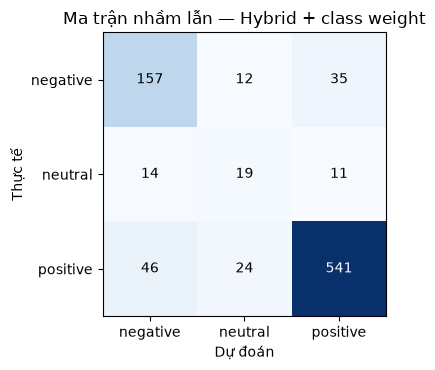

{'p_negative': 0.724, 'r_negative': 0.77, 'f1_negative': 0.746, 'p_neutral': 0.345, 'r_neutral': 0.432, 'f1_neutral': 0.384, 'p_positive': 0.922, 'r_positive': 0.885, 'f1_positive': 0.903}
Số tham số đầu phân loại: 2387715


In [8]:
p = PREDS[(FULL, SEEDS_HEAD[0])]
cm = confusion_matrix(y_test, p, labels=[0, 1, 2])
fig, ax = plt.subplots(figsize=(4.4, 3.8)); ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(3)); ax.set_xticklabels(LABELS); ax.set_yticks(range(3)); ax.set_yticklabels(LABELS)
ax.set_xlabel('Dự đoán'); ax.set_ylabel('Thực tế'); ax.set_title('Ma trận nhầm lẫn — Hybrid + class weight')
for i in range(3):
    for j in range(3): ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max()/2 else 'black')
plt.tight_layout(); plt.show()
r = RESULTS[FULL][0]
print({k: round(v, 3) for k, v in r.items() if k.startswith(('p_', 'r_', 'f1_'))})
print('Số tham số đầu phân loại:', r['n_params'])

**Đọc kết quả của mục F.** Ma trận nhầm lẫn ở ô trên là mô hình lai đầy đủ, seed 0 (hàng là nhãn thật):

| Thật \ Đoán | negative | neutral | positive |
|---|---:|---:|---:|
| negative (204) | 157 | 12 | 35 |
| neutral (44) | 14 | 19 | 11 |
| positive (611) | 46 | 24 | 541 |

- Neutral: đoán đúng 19/44 (recall 43,2%). Mô hình đoán neutral 55 lần nhưng chỉ 19 lần đúng (precision 34,5%). Neutral bị đoán sai thành negative (14) nhiều hơn thành positive (11).
- Số lỗi lớn nhất là đảo cực tính, không phải neutral: positive bị đoán thành negative (46) và negative bị đoán thành positive (35).

Để không phụ thuộc seed 0, đây là precision / recall trung bình qua 5 seed (tính từ `deep_results_runs.json`):

| Mô hình | Lớp | Precision | Recall |
|---|---|---:|---:|
| Hybrid + class weight | negative | 70,3 | 79,7 |
| | neutral | 32,8 | 40,5 |
| | positive | 93,6 | 87,0 |
| Hybrid (không class weight) | neutral | 26,1 | 23,6 |
| BERT fine-tune + class weight (3 seed) | neutral | 60,1 | 37,1 |
| BERT fine-tune (3 seed, không class weight) | neutral | 64,4 | 25,8 |

- Với lớp neutral, mô hình lai đoán neutral thường nhưng sai nhiều: chỉ ~1/3 lần đoán neutral là đúng (precision 32,8), và vẫn bỏ sót ~60% mẫu neutral thật (recall 40,5).
- Class weight kéo recall neutral của mô hình lai từ 23,6 lên 40,5 và precision cũng tăng nhẹ (26,1 → 32,8), nên F1 neutral tăng.
- BERT fine-tune chính xác hơn rõ ở neutral (precision 60–64) nhưng cũng bỏ sót nhiều (recall 26–37): lớp neutral khó cho cả hai kiểu mô hình.

## G. Hai điểm yếu của notebook 03, đo bằng số thật

Báo cáo cũ có hai lựa chọn mà nhóm chưa đo được ảnh hưởng. Ở đây đo bằng đầu phân loại lai của notebook này (BERT đóng băng, class weight). Vì vậy đây là **ước lượng độ lớn**, không phải tái hiện con số 86,61% của notebook 03 (còn khác lr, chuẩn hóa, class weight, độ dài đệm).

- **G1 – Chọn epoch trên test.** Huấn luyện 25 epoch, không early stopping, ghi kết quả test ở mỗi epoch (chỉ để báo cáo). So ba cách chọn epoch: theo validation (chuẩn); theo accuracy test cao nhất (cách của notebook 03); theo Macro F1 test cao nhất ("oracle").
- **G2 – Không mask padding.** Đệm cố định 128 token, giữ cả vector ở vị trí đệm và không mask (mask toàn True), giống cách notebook 03 làm. So với mô hình đầy đủ có mask ở mục B.

In [9]:
# ── G1. Chọn epoch trên TEST (như notebook 03) so với trên VALIDATION (chuẩn) ──────────────────
# Cùng một lần huấn luyện, không early stopping (patience = số epoch), có ghi đường cong test chỉ để báo cáo.
from scipy import stats
H1_PATH = '../results/h1_epoch_selection.csv'
if os.path.exists(H1_PATH):
    H1 = pd.read_csv(H1_PATH); print('[đã có]', H1_PATH)
else:
    rows = []
    for s in SEEDS_HEAD:
        tri, vai = SPLITS[s]
        r, _ = train_head({}, [F_bert[i] for i in tri], [y_train[i] for i in tri],
                          [F_bert[i] for i in vai], [y_train[i] for i in vai], Fte_bert, y_test, seed=s,
                          epochs=EPOCHS_HEAD, patience=EPOCHS_HEAD, lr=LR_HEAD, class_weight=True,
                          device=device, track_test=True)
        c = pd.DataFrame(r['curve'])
        rows.append(dict(seed=s,
                         chuan_acc=r['acc'], chuan_f1=r['macro_f1'],                                    # epoch chọn theo validation
                         nb03_acc=c.test_acc.max(), nb03_f1=c.loc[c.test_acc.idxmax(), 'test_macro_f1'], # epoch có accuracy TEST cao nhất (như nb03)
                         oracle_f1=c.test_macro_f1.max()))                                              # Macro F1 TEST cao nhất qua các epoch
    H1 = pd.DataFrame(rows)
    os.makedirs('../results', exist_ok=True); H1.to_csv(H1_PATH, index=False)
print((H1.drop(columns='seed') * 100).agg(['mean', 'std']).round(2).T.to_string())

def ci_str(x):
    x = np.asarray(x) * 100; n = len(x); h = stats.t.ppf(0.975, n - 1) * x.std(ddof=1) / np.sqrt(n)
    return f'{x.mean():+.2f}  [{x.mean() - h:+.2f}; {x.mean() + h:+.2f}]  (n={n})'
print('\nMức lạc quan khi chọn epoch trên test (điểm %, trung bình và CI 95% theo t):')
for lab, a, b in (('Accuracy   (nb03 − chuẩn)', 'nb03_acc', 'chuan_acc'),
                  ('Macro F1   (nb03 − chuẩn)', 'nb03_f1', 'chuan_f1'),
                  ('Macro F1   (oracle − chuẩn)', 'oracle_f1', 'chuan_f1')):
    print(f'  {lab:<28}: {ci_str(H1[a] - H1[b])}')

[đã có] ../results/h1_epoch_selection.csv
            mean   std
chuan_acc  83.03  1.25
chuan_f1   66.20  2.21
nb03_acc   84.12  0.51
nb03_f1    68.82  1.89
oracle_f1  69.23  1.46

Mức lạc quan khi chọn epoch trên test (điểm %, trung bình và CI 95% theo t):
  Accuracy   (nb03 − chuẩn)   : +1.09  [-0.26; +2.44]  (n=5)
  Macro F1   (nb03 − chuẩn)   : +2.62  [-0.87; +6.11]  (n=5)
  Macro F1   (oracle − chuẩn) : +3.03  [+0.20; +5.86]  (n=5)


In [10]:
# ── G2. KHÔNG mask padding (đệm cố định như notebook 03) so với CÓ mask ──────────────────────
def frozen_features_padded(key, pad_to=MAX_LEN):
    tok, factory = load_backbone(key)
    I_all = encode_pairs(tok, train_df.category, train_df.sentence, MAX_LEN)
    I_te  = encode_pairs(tok, test_df.category,  test_df.sentence,  MAX_LEN)
    bb = factory()
    F_all = extract_features(bb, I_all, tok.pad_token_id, device, pad_to=pad_to)
    F_te  = extract_features(bb, I_te,  tok.pad_token_id, device, pad_to=pad_to)
    del bb
    return F_all, F_te

NOMASK = f'Mask TẮT (đệm cố định {MAX_LEN}, như notebook 03) + class weight'
if not (NOMASK in RESULTS and len(RESULTS[NOMASK]) == len(SEEDS_HEAD)):      # đã có kết quả thì khỏi trích lại đặc trưng
    F_pad, Fte_pad = frozen_features_padded('bert-base-uncased')
    run_head(NOMASK, F_pad, Fte_pad, {}, class_weight=True)
    del F_pad, Fte_pad
report(NOMASK); report(FULL)
print('\nΔ Macro F1 (mask TẮT − mask BẬT):', delta(NOMASK))

Mask TẮT (đệm cố định 128, như notebook 03) + class weight {'acc': '82.61 ± 2.16', 'macro_f1': '67.54 ± 2.08', 'f1_neutral': '37.69 ± 3.70'}
Hybrid (BERT đóng băng) + class weight     {'acc': '82.89 ± 1.06', 'macro_f1': '66.60 ± 1.42', 'f1_neutral': '35.16 ± 4.34'}

Δ Macro F1 (mask TẮT − mask BẬT): +0.94  [-2.91; +4.79] n=5 (CI chứa 0)


### Kết quả G1 và G2 (5 seed, test)

**G1 – chọn epoch.** Dữ liệu: `results\h1_epoch_selection.csv`.

| Cách chọn epoch | Accuracy | Macro F1 |
|---|---:|---:|
| Theo validation (chuẩn) | 83,03 | 66,20 |
| Theo accuracy test cao nhất (như notebook 03) | 84,12 | 68,82 |
| Theo Macro F1 test cao nhất (oracle) | – | 69,23 |

Mức lạc quan so với chuẩn (trung bình, CI 95% theo t): Accuracy **+1,09** [−0,26; +2,44]; Macro F1 theo quy tắc notebook 03 **+2,62** [−0,87; +6,11]; Macro F1 oracle **+3,03** [+0,20; +5,86].
- Chọn epoch trên test làm số đẹp hơn khoảng 1 điểm Accuracy và 2–3 điểm Macro F1. Mức này khác nhau nhiều giữa các seed (Accuracy: +0,00 đến +2,91).
- Cách tính nb03 và oracle luôn cho giá trị ≥ chuẩn (vì lấy giá trị lớn nhất trên test), nên CI loại 0 không phải bằng chứng; chỉ đọc độ lớn.

**G2 – mask padding.**

| Cấu hình | Accuracy | Macro F1 | F1 neutral |
|---|---:|---:|---:|
| Có mask (mô hình đầy đủ, mục B) | 82,89 ± 1,06 | 66,60 ± 1,42 | 35,16 ± 4,34 |
| Không mask (đệm cố định 128) | 82,61 ± 2,16 | 67,54 ± 2,08 | 37,69 ± 3,70 |

Δ Macro F1 (không mask − có mask) = **+0,94** [−2,91; +4,79], n = 5: CI chứa 0.
- Trong thiết lập này (đặc trưng BERT đóng băng) **không thấy bằng chứng** rằng bỏ mask làm kết quả tệ đi. Vì vậy không viết "thiếu mask làm giảm hiệu năng". Mask vẫn đúng về mặt phương pháp (không để padding ảnh hưởng thống kê), nhưng ảnh hưởng đo được ở đây không phân biệt được với 0.
- Giả thuyết (chưa kiểm chứng): BERT vẫn cho vector có nghĩa ở vị trí đệm, nên mean-pool và attention không bị nhiễu nặng như tưởng.
- G2 chỉ cô lập mask. Các khác biệt khác với notebook 03 (đệm 128 thay vì 256, LayerNorm thay BatchNorm, AdamW thay Adam) vẫn còn.

**So với notebook 03.** Bản gốc đạt Accuracy 86,61 nhưng Macro F1 chỉ 59,67 (F1 neutral 8,51; recall neutral 4,5%). Mô hình lai ở đây đạt Accuracy 82,89 và Macro F1 66,60. Accuracy thấp hơn 3,7 điểm nhưng Macro F1 cao hơn 6,9 điểm. Chọn epoch trên test (~1 điểm Accuracy) chỉ giải thích được một phần; phần còn lại (class weight vốn làm Accuracy giảm ~0,8, lr, chuẩn hóa…) chưa được tách riêng.

## H. Kết luận (từ số liệu mục E, F và G)

**Kết quả chính (test 859 mẫu, Macro F1 trung bình ± độ lệch chuẩn):** TF-IDF (≈ 60) < Hybrid BERT đóng băng (66,6) < RoBERTa/DeBERTa đóng băng (≈ 70) ≈ BERT fine-tune (70,0) < BERT fine-tune + class weight (72,8). Trong đầu lai, **Attention là thành phần duy nhất có đóng góp**; GRU, BiLSTM và CNN chưa có bằng chứng đóng góp.

| Mô hình | Macro F1 | F1 neutral | #seed |
|---|---:|---:|---:|
| Đoán luôn positive | 27,71 | 0,00 | – |
| TF-IDF S+A + LR, cân bằng lớp (notebook 04) | 60,51 ± 1,84 | 29,65 ± 5,93 | 5 |
| TF-IDF S×A + LR, cân bằng lớp (notebook 04) | 58,89 ± 2,65 | 25,76 ± 9,77 | 5 |
| Hybrid BERT đóng băng | 63,61 ± 5,56 | 24,67 ± 14,10 | 5 |
| Hybrid BERT đóng băng + class weight | 66,60 ± 1,42 | 35,16 ± 4,34 | 5 |
| Hybrid RoBERTa đóng băng + class weight | 70,03 ± 2,16 | 40,70 ± 4,95 | 5 |
| Hybrid DeBERTa-v3 đóng băng + class weight | 69,86 ± 1,77 | 39,28 ± 1,93 | 5 |
| BERT fine-tune + [CLS] | 70,01 ± 1,49 | 36,65 ± 3,09 | 3 |
| BERT fine-tune + [CLS] + class weight | **72,81 ± 2,10** | 45,79 ± 3,66 | 3 |

### 1. Mô hình lai có hơn BERT fine-tune và TF-IDF không?
- **Hơn TF-IDF:** Hybrid + class weight cao hơn baseline TF-IDF mạnh nhất 6,09 điểm Macro F1 (66,60 so với 60,51), khoảng 3 lần độ lệch chuẩn của mỗi bên (1,42 và 1,84).
- **Hơn đầu đơn giản (mean-pool + MLP):** +4,35 điểm [+3,36; +5,34], n = 5, CI loại 0.
- **Không hơn BERT fine-tune:** fine-tune không class weight hơn mô hình lai +3,20 [+1,81; +4,59] (n = 3); fine-tune + class weight hơn +6,01 nhưng CI rất rộng [−1,04; +13,06] (n = 3). Hai số này khác phép trừ trung bình ở bảng trên vì chỉ ghép cặp ba seed chung.
- Lưu ý: phép so sánh này đổi cả đầu phân loại lẫn chế độ backbone (đóng băng so với fine-tune toàn bộ), nên chưa thể quy riêng cho kiến trúc lai.

### 2. Thành phần nào có đóng góp?
Δ = bỏ thành phần − mô hình đầy đủ (Macro F1, điểm %):

| Bỏ | Macro F1 | Δ [CI 95%] | CI |
|---|---:|---:|---|
| GRU | 67,10 ± 1,62 | +0,49 [−2,99; +3,98] | chứa 0 |
| BiLSTM | 65,75 ± 1,62 | −0,85 [−3,25; +1,55] | chứa 0 |
| Attention | 62,10 ± 1,91 | **−4,50** [−7,66; −1,34] | loại 0 |
| CNN | 66,75 ± 3,24 | +0,14 [−3,58; +3,87] | chứa 0 |
| Tất cả (mean-pool + MLP) | 62,25 ± 1,11 | **−4,35** [−5,34; −3,36] | loại 0 |

- Bỏ Attention giảm 4,50 điểm và F1 neutral giảm từ 35,16 xuống 25,39.
- Bản bỏ Attention (62,10) gần như bằng bản bỏ tất cả (62,25; chênh −0,15 [−2,98; +2,68]). Nghĩa là toàn bộ lợi thế của đầu lai so với đầu đơn giản đến từ khối Attention; GRU, BiLSTM và CNN chồng lên trên không thêm lợi ích đo được.
- Bỏ GRU hoặc CNN làm trung bình nhích lên nhẹ nhưng nằm trong nhiễu, nên chỉ viết "chưa có bằng chứng chúng cải thiện kết quả", không viết "chúng gây hại". Ablation ở đây bỏ từng thành phần một, chưa thử các tổ hợp.

### 3. Đổi backbone có đổi kết quả không?
Cùng đầu lai, backbone đóng băng, có class weight:

| Backbone | Accuracy | Macro F1 | F1 neutral | Δ so với BERT [CI 95%] |
|---|---:|---:|---:|---|
| BERT | 82,89 ± 1,06 | 66,60 ± 1,42 | 35,16 ± 4,34 | – |
| RoBERTa | 84,80 ± 1,19 | 70,03 ± 2,16 | 40,70 ± 4,95 | +3,42 [+0,47; +6,38] |
| DeBERTa-v3 | 85,70 ± 2,39 | 69,86 ± 1,77 | 39,28 ± 1,93 | +3,26 [+0,39; +6,13] |

- RoBERTa và DeBERTa-v3 cùng cao hơn BERT khoảng 3,3–3,4 điểm. Cận dưới của CI chỉ sát 0,4–0,5 và có nhiều phép so sánh cùng lúc, nên đây là xu hướng khá nhất quán chứ chưa phải bằng chứng mạnh.
- RoBERTa và DeBERTa không phân biệt được với nhau (chênh −0,16 [−4,99; +4,66]). Thời gian trích đặc trưng trên CPU dao động giữa các lần chạy (BERT 92–104 s, RoBERTa 85–356 s, DeBERTa-v3 998–1 820 s), nhưng DeBERTa-v3 luôn chậm nhất mà không tốt hơn RoBERTa.
- Đặc trưng đóng băng của RoBERTa và DeBERTa (≈ 70) đạt ngang BERT fine-tune thường (70,01; chênh RoBERTa − BERT fine-tune là −1,41 [−3,20; +0,39], n = 3). Không mở rộng kết luận này sang trường hợp fine-tune RoBERTa/DeBERTa vì chưa chạy.

### 4. Class weight cải thiện neutral bao nhiêu, đánh đổi gì?

| Chỉ số | BERT fine-tune: không → có | Hybrid: không → có |
|---|---:|---:|
| F1 neutral | 36,65 → 45,79 (**+9,14**) | 24,67 → 35,16 (**+10,49**) |
| F1 negative | 80,38 → 79,89 (−0,49) | 75,59 → 74,51 (−1,08) |
| F1 positive | 92,99 → 92,76 (−0,23) | 90,57 → 90,14 (−0,43) |
| Macro F1 | 70,01 → 72,81 (**+2,80**) | 63,61 → 66,60 (**+2,99**) |
| Accuracy | 87,78 → 87,50 (−0,28) | 83,73 → 82,89 (−0,84) |
| Δ Macro F1 ghép cặp [CI 95%] | +2,81 [−4,78; +10,40], n = 3 | +2,99 [−4,86; +10,84], n = 5 |

- F1 neutral tăng ở cả hai nhóm mô hình, đổi lại mất rất ít ở negative, positive và Accuracy.
- Với mô hình lai, class weight còn làm kết quả ổn định hơn: độ lệch chuẩn Macro F1 giảm từ 5,56 xuống 1,42. Nguyên nhân là ở một seed mô hình không có class weight không đoán neutral lần nào (F1 neutral = 0 ở seed 0).
- Hiệu Macro F1 ghép cặp có CI rất rộng và chứa 0, nên chỉ kết luận về xu hướng: class weight tăng F1 neutral nhất quán, còn mức tăng Macro F1 chưa được xác định chắc.

### 5. Hai điểm yếu của notebook 03 (mục G)
- Chọn epoch trên test làm kết quả đẹp hơn khoảng +1,1 điểm Accuracy và +2,6 đến +3,0 điểm Macro F1 trong thiết lập này. Mức tác động có thật nhưng không lớn bằng khoảng cách giữa 86,61% và các số của notebook này.
- Việc không mask padding **không** làm kết quả tệ đi một cách đo được (Δ = +0,94 [−2,91; +4,79]).

### Giới hạn
- Chỉ một bộ dữ liệu (Res16), test 859 mẫu, neutral 44 mẫu: mọi chênh lệch nhỏ đều không chắc.
- BERT fine-tune chỉ chạy 3 seed; các mô hình đóng băng chạy 5 seed. Các seed chỉ đổi cách tách train/validation, không đổi tập test.
- Chưa tinh chỉnh siêu tham số cho đầu lai (lr, số chiều ẩn, dropout) và có nhiều phép so sánh cùng lúc, nên không dùng cụm "có ý nghĩa thống kê".